In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from scipy.spatial.distance import cdist
from scipy.stats import wasserstein_distance
import ot
import itertools
from umap import UMAP

In [8]:
animal_data = pd.read_csv("Tierdaten/non_inv_params_long_list_constant_speed_all.csv", sep=';')
dfs = {animal: df_group for animal, df_group in animal_data.groupby('animal')}

print(dfs.keys())
print(len(dfs.keys()))
print(animal_data.groupby('animal').size())
print(animal_data.groupby('animal').size()>750)
counts = animal_data.groupby('animal').size()
all_ids_500 = counts[counts > 500].index.tolist()
print(all_ids_500)
all_ids_750 = counts[counts > 750].index.tolist()
print(all_ids_750)
all_ids_1000 = counts[counts > 1000].index.tolist()
print(all_ids_1000)

dict_keys([1, 3, 4, 7, 8, 10, 11, 13, 16, 17, 19, 20, 101, 102, 105, 107, 108, 111, 113, 502, 503, 505, 506])
23
animal
1      1853
3      1562
4      2381
7       915
8      1777
10     1508
11     2215
13      777
16     1828
17       63
19      934
20     1433
101     172
102     234
105     303
107     946
108     509
111     758
113    1449
502     298
503     471
505      81
506     178
dtype: int64
animal
1       True
3       True
4       True
7       True
8       True
10      True
11      True
13      True
16      True
17     False
19      True
20      True
101    False
102    False
105    False
107     True
108    False
111     True
113     True
502    False
503    False
505    False
506    False
dtype: bool
[1, 3, 4, 7, 8, 10, 11, 13, 16, 19, 20, 107, 108, 111, 113]
[1, 3, 4, 7, 8, 10, 11, 13, 16, 19, 20, 107, 111, 113]
[1, 3, 4, 8, 10, 11, 16, 20, 113]


In [9]:
#all_ids = [1, 3, 4, 8, 10, 11, 13, 16, 19, 20, 102, 105, 107, 108, 111, 113]
all_ids = all_ids_500

dfs_selected = {a: dfs[a] for a in all_ids if a in dfs}

df_selected = pd.concat(dfs_selected.values())

print(df_selected.groupby('animal').size())

df_selected.groupby('animal')['intervention'].value_counts()
df_selected.groupby('animal')['controller'].value_counts()

animal
1      1853
3      1562
4      2381
7       915
8      1777
10     1508
11     2215
13      777
16     1828
19      934
20     1433
107     946
108     509
111     758
113    1449
dtype: int64


animal  controller
1       2             1853
3       2             1270
        4              292
4       2             1761
        5              357
        4              263
7       2              915
8       2             1777
10      2             1508
11      2             2215
13      2              777
16      2             1828
19      2              934
20      2             1433
107     2              946
108     2              509
111     2              758
113     2             1449
Name: count, dtype: int64

In [10]:
cols = df_selected.columns[14:].drop("syst_share_p_head_by_byp_flow")
df_features = df_selected[cols]

data = {}
for aid in all_ids:
    mask = df_selected['animal'] == aid

    X = df_features[mask].reset_index(drop=True)
    Y = df_selected.loc[mask, ['sw']].reset_index(drop=True)
    Y.columns = ['target']

    data[aid] = (X, Y)


--- A. Target (Y) Pairwise 1D Wasserstein Distance Matrix ---
             Anim 1     Anim 3     Anim 4     Anim 7     Anim 8    Anim 10  \
Anim 1       0.0000   503.2089   545.9717   554.1619   606.5296   982.3989   
Anim 3     503.2089     0.0000   945.2243   992.4234  1044.7911   665.3659   
Anim 4     545.9717   945.2243     0.0000   321.3609   311.0608  1378.9857   
Anim 7     554.1619   992.4234   321.3609     0.0000   135.0082  1462.4658   
Anim 8     606.5296  1044.7911   311.0608   135.0082     0.0000  1514.8336   
Anim 10    982.3989   665.3659  1378.9857  1462.4658  1514.8336     0.0000   
Anim 11    315.5810   480.8383   490.3391   513.9269   567.7927   949.4748   
Anim 13   1022.8381   532.3165  1443.4401  1518.7286  1571.0963   691.6972   
Anim 16    589.7745   130.0944  1013.1227  1042.8860  1099.4679   576.5781   
Anim 19    953.8710   457.0005  1377.6837  1425.5019  1480.2333   695.1871   
Anim 20    966.3575   465.7717  1397.1450  1427.3588  1482.2587   656.0345   
A

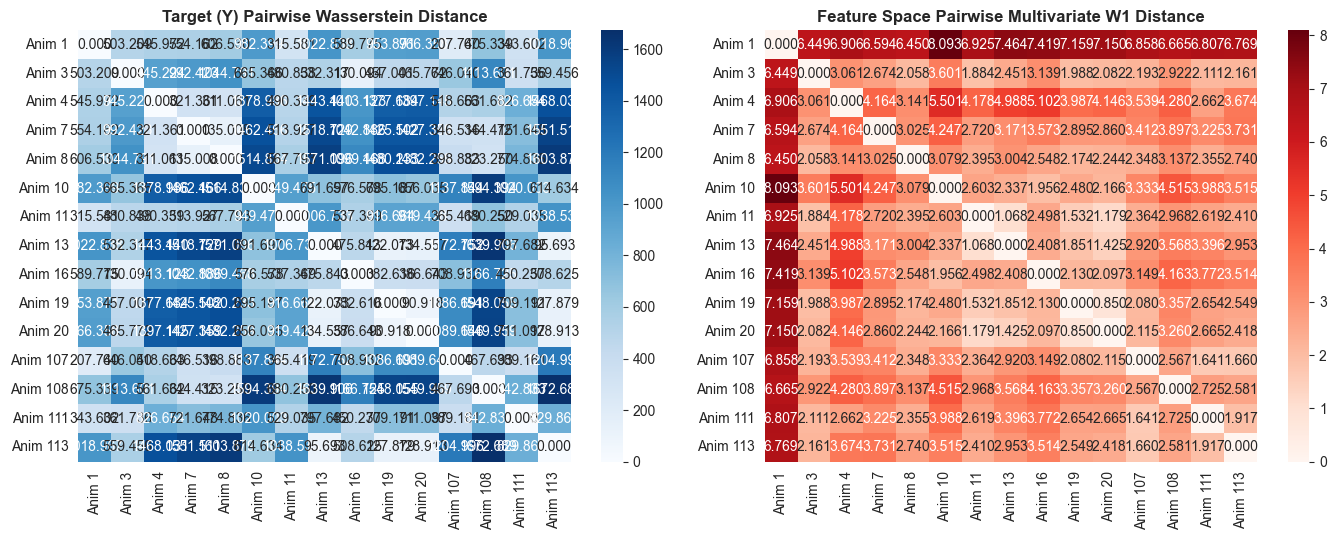

In [11]:
# W Distnace
# 1. Fit scaler on all data combined to ensure a uniform feature metric space
all_X_concat = pd.concat([data[aid][0] for aid in all_ids], axis=0)
scaler = StandardScaler()
scaler.fit(all_X_concat)

# 2. Store scaled features and target values per animal
scaled_X = {aid: scaler.transform(data[aid][0]) for aid in all_ids}
targets = {aid: data[aid][1]['target'].values for aid in all_ids}

animal_labels = [f"Anim {aid}" for aid in all_ids]
n_animals = len(all_ids)

# 3. Initialize distance matrices
y_w_matrix = pd.DataFrame(0.0, index=animal_labels, columns=animal_labels)
multi_w_matrix = pd.DataFrame(0.0, index=animal_labels, columns=animal_labels)


# 4. Compute pairwise distances
for i, id1 in enumerate(all_ids):
    for j, id2 in enumerate(all_ids):
        if i < j:
            # --- A. 1D Target (Y) Wasserstein Distance ---
            w_y = wasserstein_distance(targets[id1], targets[id2])
            y_w_matrix.iloc[i, j] = w_y
            y_w_matrix.iloc[j, i] = w_y  # Symmetric matrix

            # --- B. Multivariate Feature Space Wasserstein Distance ---
            X1 = scaled_X[id1]
            X2 = scaled_X[id2]

            # Cost Matrix: Euclidean distances between all sample pairs
            M = ot.dist(X1, X2, metric='euclidean')
            a = ot.unif(len(X1))
            b = ot.unif(len(X2))

            # Compute exact 1-Wasserstein distance (consistent with the 1-D W1 used elsewhere)
            w1_dist = ot.emd2(a, b, M, numItermax=1_000_000)

            multi_w_matrix.iloc[i, j] = w1_dist
            multi_w_matrix.iloc[j, i] = w1_dist

# 5. Print Tabular Results
print("\n--- A. Target (Y) Pairwise 1D Wasserstein Distance Matrix ---")
print(y_w_matrix.round(4))

print("\n--- B. Full Feature Space Pairwise Multivariate W1 Distance Matrix ---")
print(multi_w_matrix.round(4))

# 6. Plot Pairwise Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(y_w_matrix, annot=True, fmt=".3f", cmap="Blues", cbar=True, ax=axes[0])
axes[0].set_title("Target (Y) Pairwise Wasserstein Distance", fontsize=12, fontweight='bold')

sns.heatmap(multi_w_matrix, annot=True, fmt=".3f", cmap="Reds", cbar=True, ax=axes[1])
axes[1].set_title("Feature Space Pairwise Multivariate W1 Distance", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

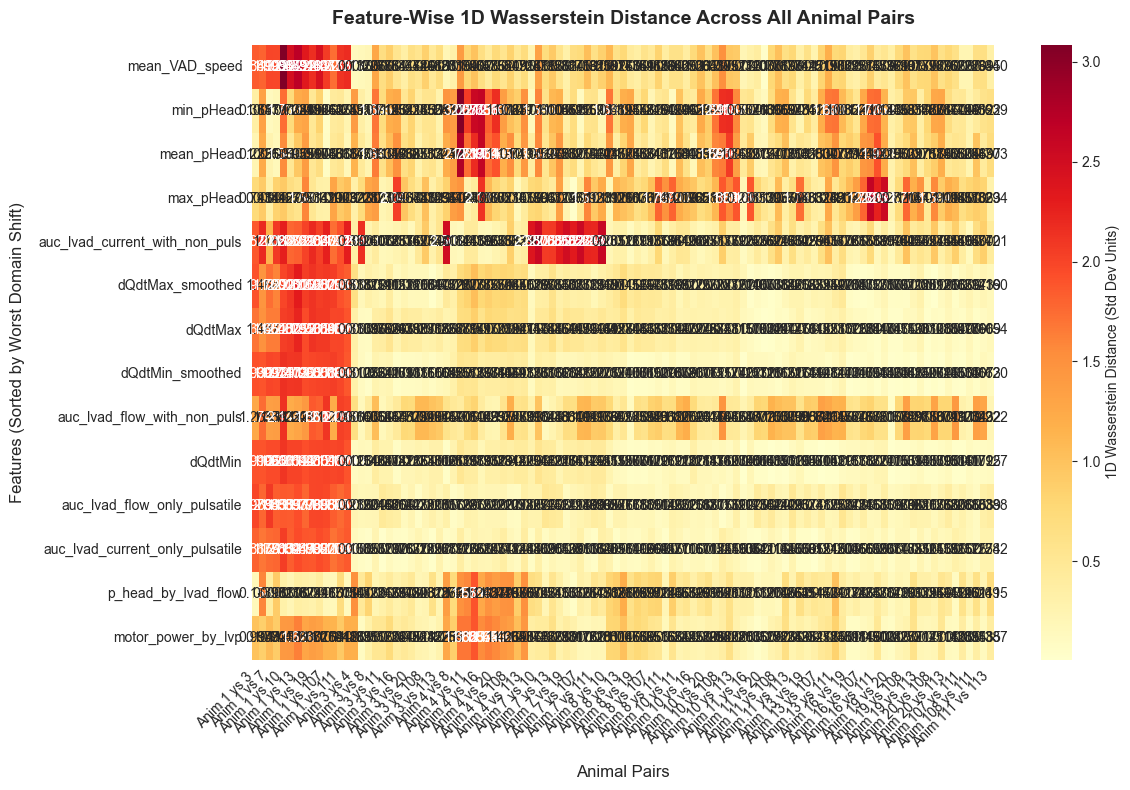

In [12]:
# W Distance per Feature
# 1. Fit scaler on all feature data combined for a uniform metric space
all_X_concat = pd.concat([data[aid][0] for aid in all_ids], axis=0)
scaler = StandardScaler()
scaler.fit(all_X_concat)

# 2. Scale features per animal while keeping feature column names
scaled_data = {}
for aid in all_ids:
    X_scaled_arr = scaler.transform(data[aid][0])
    scaled_data[aid] = pd.DataFrame(X_scaled_arr, columns=data[aid][0].columns)

# Get feature names (or indices)
sample_cols = data[all_ids[0]][0].columns
feature_names = [f"Feature {col}" if isinstance(col, int) else str(col) for col in sample_cols]

# 3. Generate all unique animal pairs (10 pairs for 5 animals)
animal_pairs = list(itertools.combinations(all_ids, 2))
pair_labels = [f"Anim {a1} vs {a2}" for a1, a2 in animal_pairs]

# Initialize matrix: Rows = Features, Columns = Animal Pairs
feature_w_matrix = pd.DataFrame(0.0, index=feature_names, columns=pair_labels)

# 4. Compute 1D Wasserstein distance per feature per animal pair
for (a1, a2), pair_label in zip(animal_pairs, pair_labels):
    df1 = scaled_data[a1]
    df2 = scaled_data[a2]
    
    for orig_col, feat_label in zip(sample_cols, feature_names):
        wd = wasserstein_distance(df1[orig_col], df2[orig_col])
        feature_w_matrix.loc[feat_label, pair_label] = wd

# Sort features by maximum shift observed across any pair (worst offenders at the top)
feature_w_matrix['max_shift'] = feature_w_matrix.max(axis=1)
feature_w_matrix = feature_w_matrix.sort_values(by='max_shift', ascending=False).drop(columns=['max_shift'])

# 5. Plot the Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    feature_w_matrix, 
    annot=True, 
    fmt=".3f", 
    cmap="YlOrRd", 
    cbar_kws={'label': '1D Wasserstein Distance (Std Dev Units)'}
)

plt.title("Feature-Wise 1D Wasserstein Distance Across All Animal Pairs", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Animal Pairs", fontsize=12, labelpad=10)
plt.ylabel("Features (Sorted by Worst Domain Shift)", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
# split missing Anims into CSV files
# import os
# 
# EXPORT_CSV = False   # set True only on the machine where out_dir exists
# out_dir = "C:/Users/leona/PythonScripts/MasterThesis/Tierdaten/"  # change as needed
# 
# animals = [7, 11, 13, 16, 19, 20, 102, 105, 107, 108, 111, 113]
# 
# for aid in (animals if EXPORT_CSV else []):
#     os.makedirs(out_dir, exist_ok=True)
#     mask = df_selected['animal'] == aid
# 
#     X = df_features[mask].reset_index(drop=True)
#     Y = df_selected.loc[mask, ['sw']].reset_index(drop=True)
#     Y.columns = ['target']
# 
#     X.to_csv(os.path.join(out_dir, f"X_anim{aid}.csv"), header=False, index=False)
#     Y.to_csv(os.path.join(out_dir, f"Y_anim{aid}.csv"), header=False, index=False)

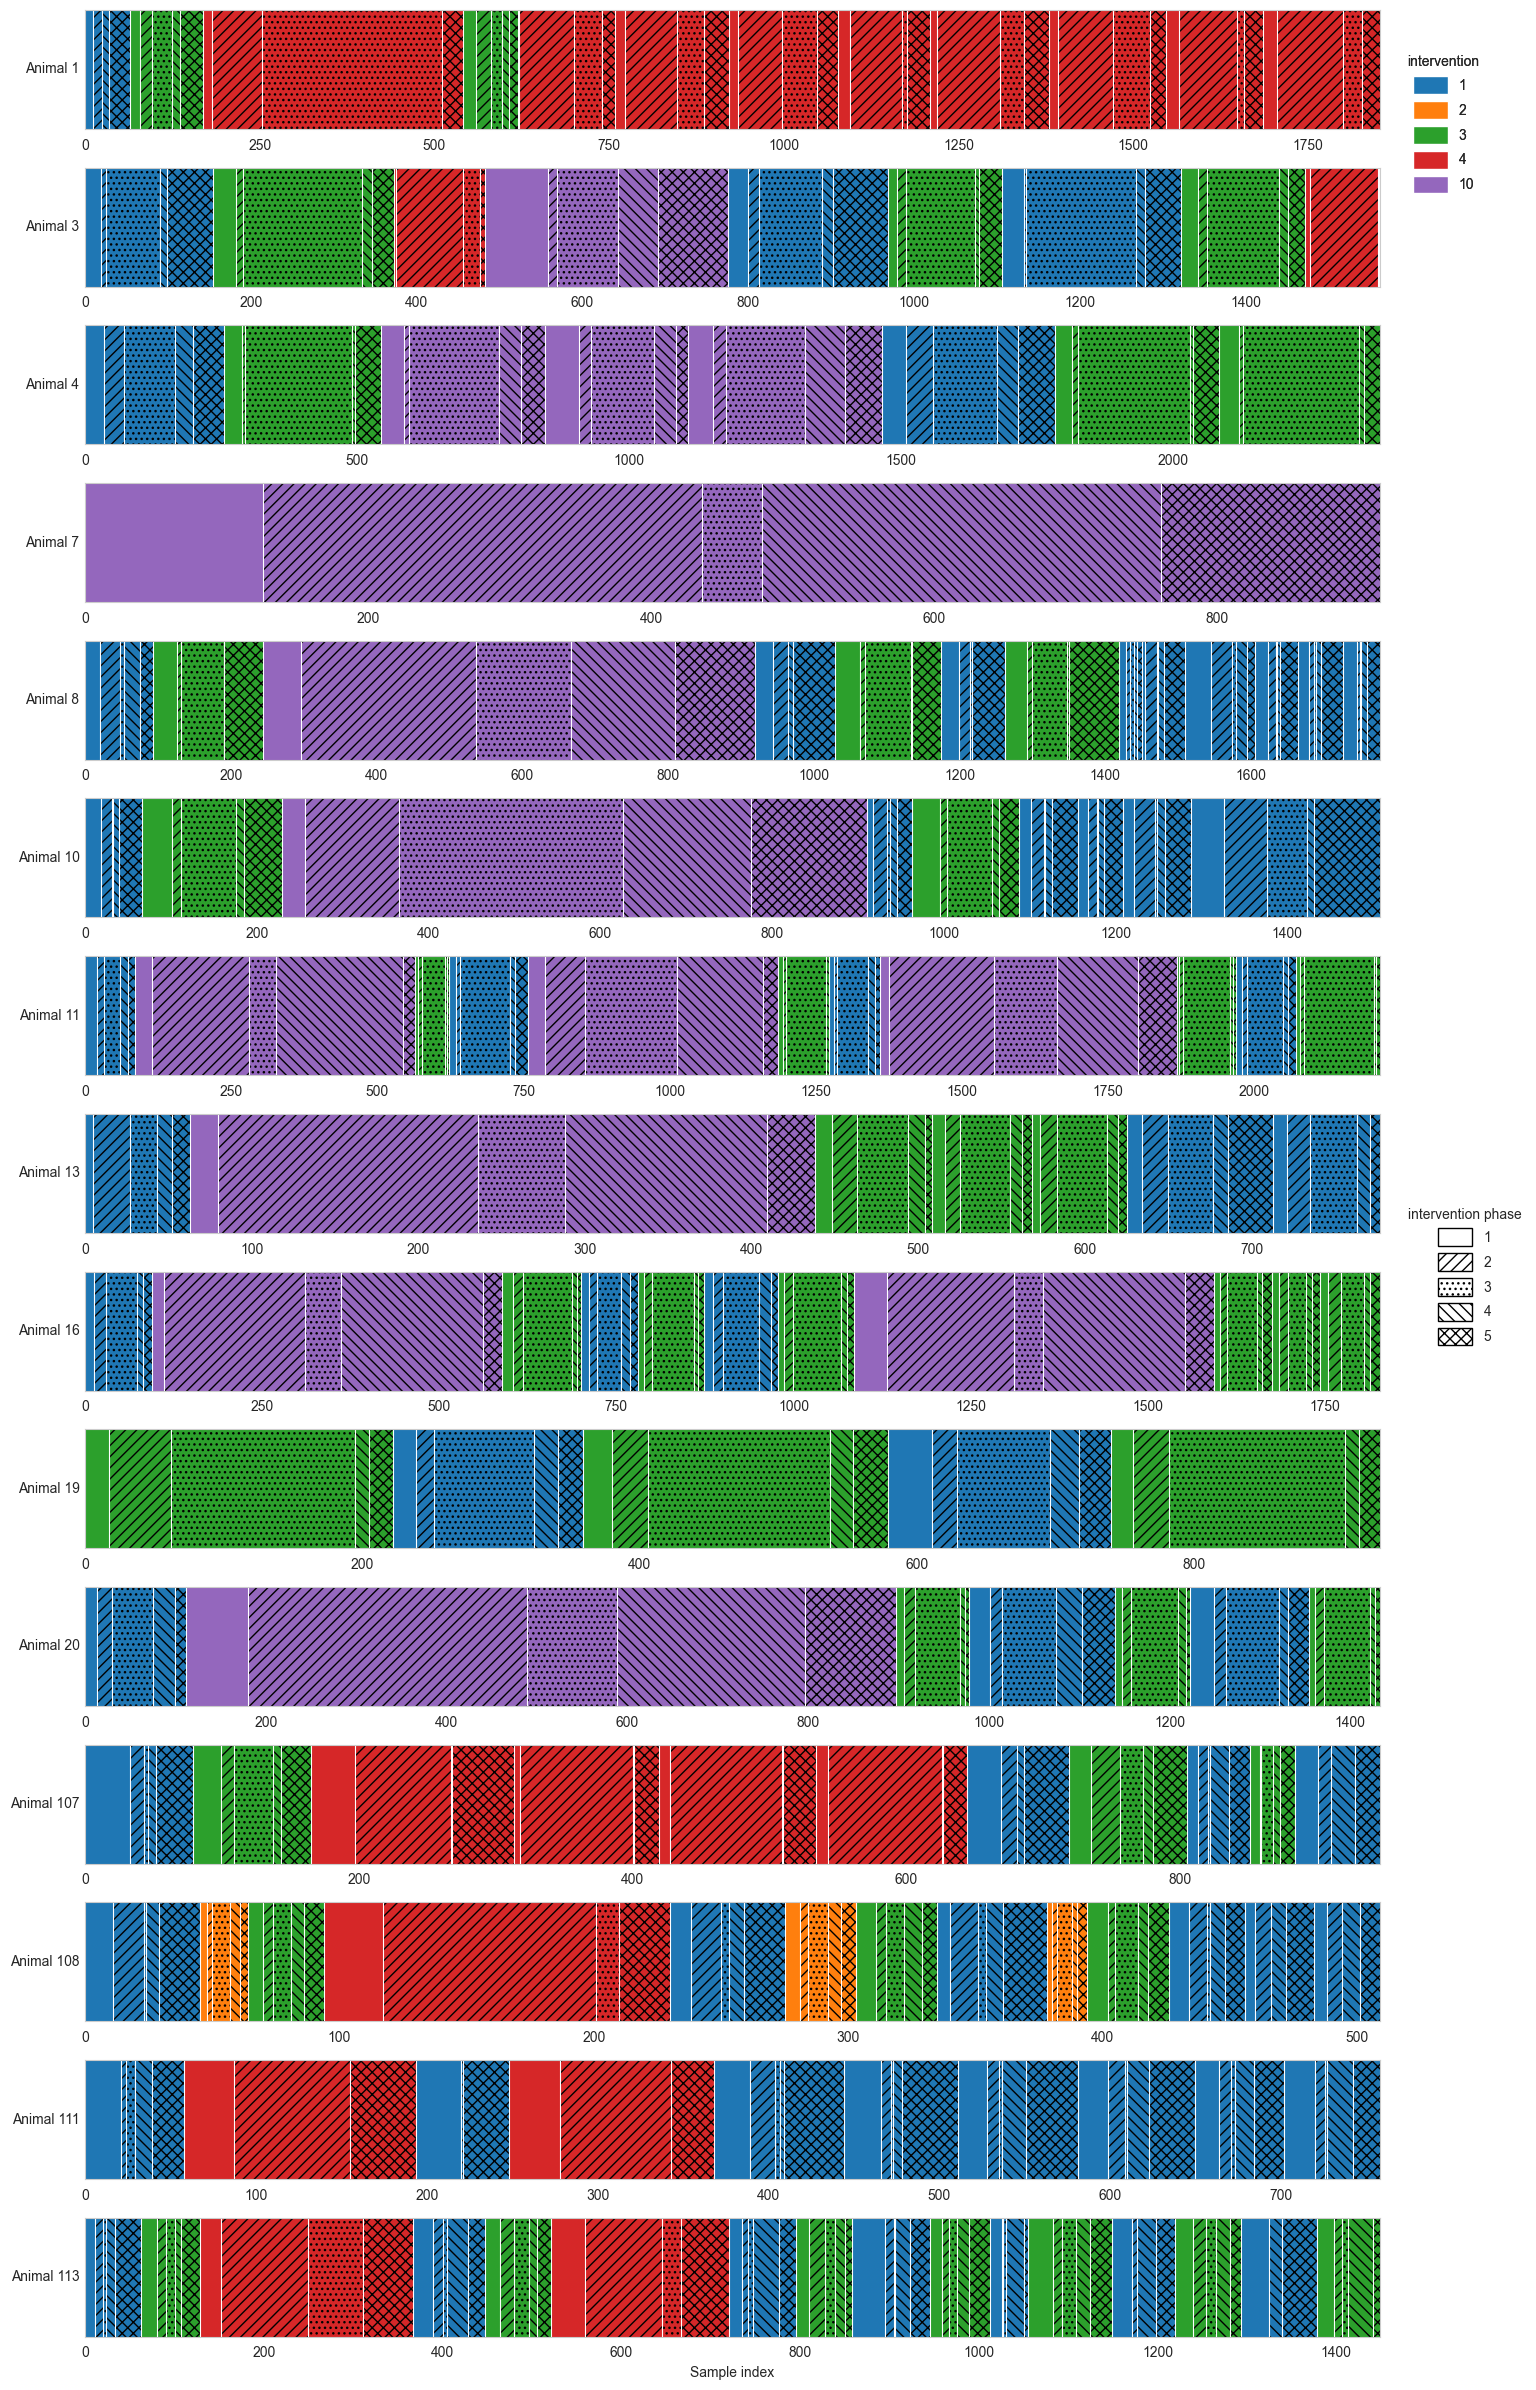

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def num_key(x):
    # numeric sort where possible (1, 2, 3, 4, 10), otherwise alphabetical
    try:
        return (0, float(x))
    except (TypeError, ValueError):
        return (1, str(x))

phases = sorted(pd.unique(df_selected['intervention'].dropna()), key=num_key)
sub_phases = sorted(pd.unique(df_selected['intervention_phase'].dropna()), key=num_key)

cmap = plt.get_cmap('tab10' if len(phases) <= 10 else 'tab20')
color_of = {p: cmap(i % cmap.N) for i, p in enumerate(phases)}
hatches = ['', '///', '...', 'xxx', '\\\\\\', '+++', 'ooo', '---']
hatch_of = {p: hatches[i % len(hatches)] for i, p in enumerate(sub_phases)}
p4 = next(p for p in hatch_of if num_key(p) == (0, 4.0))
p5 = next(p for p in hatch_of if num_key(p) == (0, 5.0))
hatch_of[p4], hatch_of[p5] = hatch_of[p5], hatch_of[p4]

fig, axes = plt.subplots(len(dfs_selected), 1, figsize=(14, 1.6 * len(dfs_selected)))
axes = np.atleast_1d(axes)

for ax, (animal, df_a) in zip(axes, dfs_selected.items()):
    d = df_a[['intervention', 'intervention_phase']].reset_index(drop=True)
    key = d['intervention'].astype(str) + '|' + d['intervention_phase'].astype(str)
    seg_id = (key != key.shift()).cumsum()

    for _, seg in d.groupby(seg_id):
        start, end = seg.index[0], seg.index[-1] + 1
        iv, ph = seg['intervention'].iloc[0], seg['intervention_phase'].iloc[0]
        ax.axvspan(start, end,
                   facecolor=color_of.get(iv, 'lightgrey'),
                   hatch=hatch_of.get(ph, ''),
                   edgecolor='black', lw=0)
        if start > 0:
            ax.axvline(start, color='white', lw=0.8)

    ax.set_xlim(0, len(d))
    ax.set_yticks([])
    ax.set_ylabel(f'Animal {animal}', rotation=0, ha='right', va='center')

axes[-1].set_xlabel('Sample index')

iv_handles = [mpatches.Patch(facecolor=color_of[p], label=str(p)) for p in phases]
ph_handles = [mpatches.Patch(facecolor='white', edgecolor='black',
                             hatch=hatch_of[p], label=str(p)) for p in sub_phases]

legend_kw = dict(loc='upper left', frameon=False,
                 handlelength=2.5, handleheight=1.6,
                 labelspacing=0.5, borderaxespad=0.5)

leg1 = fig.legend(handles=iv_handles, title='intervention',
                  bbox_to_anchor=(1.0, 0.98), **legend_kw)
fig.legend(handles=ph_handles, title='intervention phase',
           bbox_to_anchor=(1.0, 0.50), **legend_kw)
fig.add_artist(leg1)

plt.tight_layout()
plt.savefig("intervention_phases.pdf", bbox_inches="tight")
plt.show()

In [13]:
# =====================================================================
# DATA SECTION — thesis figures (builds on the cells above)
# Uses: data, all_ids, dfs_selected, df_selected, df_features, scaled_X, targets,
#       y_w_matrix, multi_w_matrix, feature_w_matrix, color_of, hatch_of,
#       phases, sub_phases, num_key
# Run the cells above first. All figures are saved as PDF to FIG_DIR.
# All distances are 1-Wasserstein (W1) on pooled z-scored features.
# =====================================================================
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
import matplotlib.patches as mpatches

MAIN_IDS = [1, 3, 4, 8, 10]       # main LOO subset (original IDs), highlighted everywhere
TARGET_ID = 1                     # original ID of the animal whose shift is discussed in the text
FIG_DIR = "figures"
TARGET_NAME = "Strokework"
TARGET_UNIT = ""                  # e.g. "mJ"
SEED = 0
TEXTWIDTH = 6.3                   # inches, ~ LaTeX \textwidth

# Colours. HEAT_CMAP is used for all distance heatmaps; it runs from white through the blue of
# "vlag" to navy so it matches the correlation plot. Alternatives: "Blues", "crest", "mako_r", "cividis_r".
HEAT_CMAP = sns.blend_palette(["#f7f9fc", sns.color_palette("vlag", 9)[0], "#16324f"], n_colors=256, as_cmap=True)
MAIN_PALETTE = "muted"            # palette for the main-subset animals ("deep", "colorblind", "Set2", ...)
HEAT_KW = dict(linewidths=0.5, linecolor="white")
XLIM_PCT = (1, 99)                # Fig. 5 / A2: x-range cropped to these percentiles (state this in the caption)

os.makedirs(FIG_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)
plt.rcParams.update({
    "font.size": 10, "axes.labelsize": 10, "axes.titlesize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "figure.dpi": 110, "savefig.bbox": "tight", "pdf.fonttype": 42,
})

main_ids = [a for a in MAIN_IDS if a in all_ids]
other_ids = [a for a in all_ids if a not in main_ids]
raw_feat_names = [str(c) for c in df_features.columns]
# Plot labels = feature names from the thesis table (tab:features)
FEATURE_LABELS = {
    "mean_VAD_speed":                  "Mean pump speed",
    "mean_pHead":                      "Mean pressure head",
    "min_pHead":                       "Minimum pressure head",
    "max_pHead":                       "Maximum pressure head",
    "p_head_by_lvad_flow":             "Pressure head–flow ratio",
    "dQdtMax":                         "Maximum flow acceleration",
    "dQdtMin":                         "Maximum flow deceleration",
    "dQdtMax_smoothed":                "Smoothed max. flow acceleration",
    "dQdtMin_smoothed":                "Smoothed max. flow deceleration",
    "auc_lvad_flow_with_non_puls":     "Total flow integral",
    "auc_lvad_flow_only_pulsatile":    "Pulsatile flow integral",
    "auc_lvad_current_with_non_puls":  "Total current integral",
    "auc_lvad_current_only_pulsatile": "Pulsatile current integral",
    "motor_power_by_lvp":              "Motor power–LV pressure ratio",
}
missing = [c for c in raw_feat_names if c not in FEATURE_LABELS]
if missing:
    print("No table name for:", missing, "-> using the column name")
feat_names = [FEATURE_LABELS.get(c, c.replace("_", " ")) for c in raw_feat_names]
n_feat = len(feat_names)

Xz = scaled_X                     # pooled z-scoring over all_ids (cell above)
Y = targets
y_pooled_sd = np.concatenate([Y[a] for a in all_ids]).std()

lab = lambda a: f"Anim {a}"       # label used in figures and to index the W matrices above
disp = lab
ids_disp_order = main_ids + sorted(other_ids)   # main subset first, then the rest

pal_main = dict(zip(main_ids, sns.color_palette(MAIN_PALETTE, len(main_ids))))
OTHER_COLOR = "0.72"
col_of = lambda a: pal_main.get(a, OTHER_COLOR)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.pdf"))
    plt.show()

def bold_main(tick_labels, ids_on_axis):
    for t, a in zip(tick_labels, ids_on_axis):
        if a in main_ids:
            t.set_fontweight("bold")

print(f"{len(all_ids)} animals, main subset: {[disp(a) for a in main_ids]}, pooled target SD: {y_pooled_sd:.2f}")

15 animals, main subset: ['Anim 1', 'Anim 3', 'Anim 4', 'Anim 8', 'Anim 10'], pooled target SD: 1049.74


In [10]:
# Table 1 — dataset overview (all animals); paste the LaTeX into the thesis (needs booktabs)
n_iv = df_selected.groupby("animal")["intervention"].nunique()
overview = pd.DataFrame({
    "Animal": [disp(a) for a in ids_disp_order],
    "Samples": [len(Y[a]) for a in ids_disp_order],
    "Mean": [Y[a].mean() for a in ids_disp_order],
    "SD": [Y[a].std() for a in ids_disp_order],
    "Min": [Y[a].min() for a in ids_disp_order],
    "Max": [Y[a].max() for a in ids_disp_order],
    "Skew": [pd.Series(Y[a]).skew() for a in ids_disp_order],
    "Interventions": [int(n_iv.get(a, 0)) for a in ids_disp_order],
})
print(overview.round(2).to_string(index=False))
print(overview.to_latex(index=False, float_format="%.1f",
      caption=f"Per-animal sample counts and {TARGET_NAME.lower()} statistics.",
      label="tab:data_overview"))

for a in ids_disp_order:
    n_neg = int((Y[a] < 0).sum())
    if n_neg:
        print(f"{disp(a)}: {n_neg} negative {TARGET_NAME.lower()} values -> explain or treat as artifacts")

  Animal  Samples    Mean      SD     Min     Max  Skew  Interventions
  Anim 1     1853 2959.66  908.01  -75.10 4424.97 -1.16              3
  Anim 3     1562 2521.39  760.45  -79.00 4361.95  0.07              4
  Anim 4     2381 3430.34 1252.68  614.57 6223.23 -0.34              3
  Anim 8     1777 3566.19  894.28  776.39 5326.08  0.02              3
 Anim 10     1508 2051.35 1167.44  192.47 5128.88  0.89              3
  Anim 7      915 3513.82  839.80 1818.39 5442.19  0.28              1
 Anim 11     2215 3000.68 1054.37   34.53 5774.55  0.06              3
 Anim 13      777 1995.09  444.28  579.24 2844.54 -0.70              3
 Anim 16     1828 2470.93  800.66 1109.05 5007.97  0.48              3
 Anim 19      934 2088.32  474.10 1082.35 3344.60 -0.30              2
 Anim 20     1433 2086.46  475.05 1098.72 3240.58  0.28              3
Anim 107      946 3167.30  729.55  427.71 4707.65 -0.66              3
Anim 108      509 3635.00  724.16  736.74 4780.35 -1.33              4
Anim 1

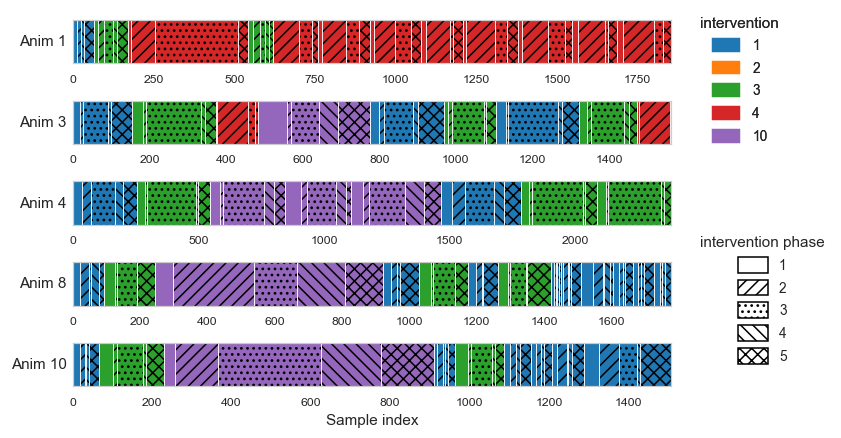

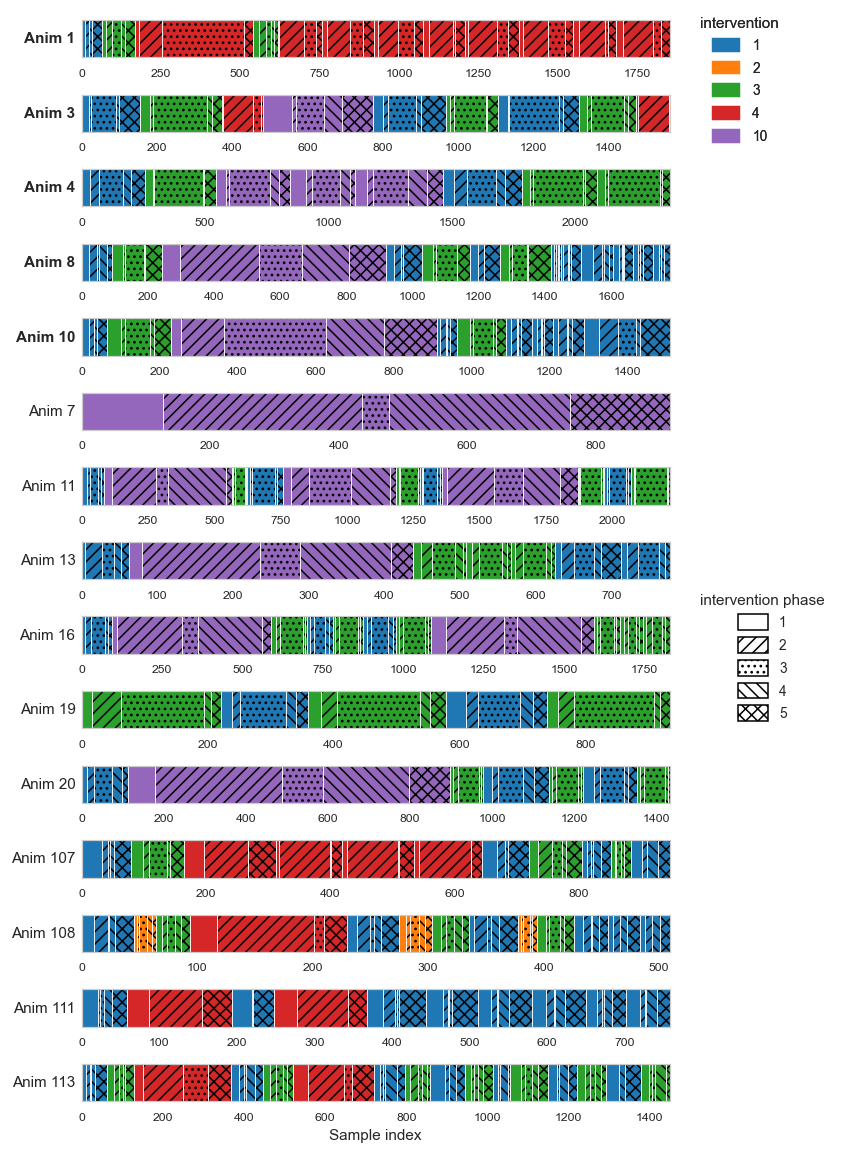

In [11]:
# Figure 1 (main subset) and Figure A0 (all animals) — experimental protocol
def plot_protocol(ids, name, row_h):
    ids = [a for a in ids if a in dfs_selected]
    fig, axes = plt.subplots(len(ids), 1, figsize=(TEXTWIDTH, row_h * len(ids)))   # own x-axis per animal
    axes = np.atleast_1d(axes)
    for ax, animal in zip(axes, ids):
        d = dfs_selected[animal][["intervention", "intervention_phase"]].reset_index(drop=True)
        key = d["intervention"].astype(str) + "|" + d["intervention_phase"].astype(str)
        for _, seg in d.groupby((key != key.shift()).cumsum()):
            start, end = seg.index[0], seg.index[-1] + 1
            iv, ph = seg["intervention"].iloc[0], seg["intervention_phase"].iloc[0]
            ax.axvspan(start, end, facecolor=color_of.get(iv, "lightgrey"),
                       hatch=hatch_of.get(ph, ""), edgecolor="black", lw=0)
            if start > 0:
                ax.axvline(start, color="white", lw=0.6)
        ax.set_xlim(0, len(d)); ax.set_yticks([])
        ax.tick_params(axis="x", labelsize=8)
        ax.set_ylabel(disp(animal), rotation=0, ha="right", va="center",
                      fontweight="bold" if animal in main_ids and len(ids) > len(main_ids) else "normal")
    axes[-1].set_xlabel("Sample index")
    kw = dict(loc="upper left", frameon=False, handlelength=2.2, handleheight=1.4)
    leg1 = fig.legend(handles=[mpatches.Patch(facecolor=color_of[p], label=str(p)) for p in phases],
                      title="intervention", bbox_to_anchor=(1.0, 1.0), **kw)
    fig.legend(handles=[mpatches.Patch(facecolor="white", edgecolor="black", hatch=hatch_of[p], label=str(p))
                        for p in sub_phases],
               title="intervention phase", bbox_to_anchor=(1.0, 0.5), **kw)
    fig.add_artist(leg1)
    plt.tight_layout()
    save(fig, name)

plot_protocol(main_ids, "fig1_intervention_phases", row_h=0.8)
if other_ids:
    plot_protocol(ids_disp_order, "figA0_intervention_phases_all", row_h=0.7)

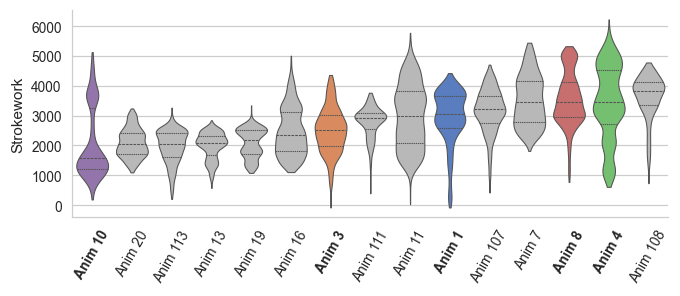

In [12]:
# Figure 2 — label shift: target distribution per animal (sorted by median, main subset in colour/bold)
order_y = sorted(all_ids, key=lambda a: np.median(Y[a]))
df_y = pd.concat([pd.DataFrame({"Animal": disp(a), TARGET_NAME: Y[a]}) for a in order_y])
fig, ax = plt.subplots(figsize=(TEXTWIDTH, 2.8))
sns.violinplot(data=df_y, x="Animal", y=TARGET_NAME, hue="Animal", order=[disp(a) for a in order_y],
               palette={disp(a): col_of(a) for a in all_ids}, inner="quartile", cut=0,
               linewidth=0.7, density_norm="width", legend=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel(f"{TARGET_NAME} [{TARGET_UNIT}]" if TARGET_UNIT else TARGET_NAME)
ax.tick_params(axis="x", rotation=60 if len(all_ids) > 8 else 45)
bold_main(ax.get_xticklabels(), order_y)
sns.despine(ax=ax)
plt.tight_layout()
save(fig, "fig2_target_distribution")

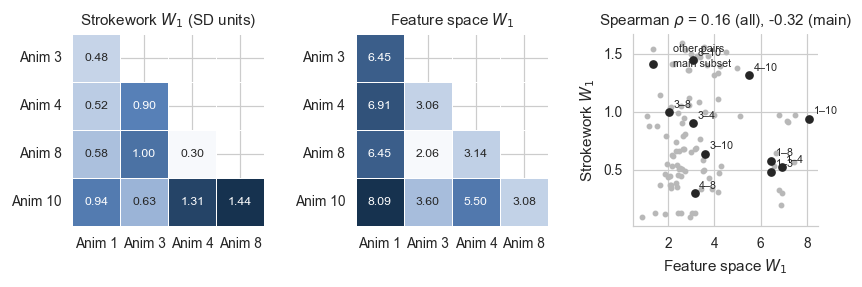

Spearman all pairs:  rho=0.157, p=0.11, n=105
Spearman main pairs: rho=-0.321, p=0.365, n=10 (descriptive only)


In [14]:
# Figure 3 — KEY FIGURE: target distance vs. feature distance (both W1)
# Left/middle: main subset (lower triangle). Right: every animal pair; main-subset pairs in black.
# If only covariate shift were present, the two distances would rank pairs similarly.
Wy = y_w_matrix / y_pooled_sd          # target W1 in pooled-SD units
Wx = multi_w_matrix                    # exact multivariate W1 on full data, pooled z-scored features
ml = [lab(a) for a in main_ids]
md_ = [disp(a) for a in main_ids]
Km = len(ml)

fig, axes = plt.subplots(1, 3, figsize=(TEXTWIDTH * 1.25, 2.7), gridspec_kw={"width_ratios": [1, 1, 0.9]})
tri = ~np.tril(np.ones((Km - 1, Km - 1), dtype=bool))
for ax, M, title in [(axes[0], Wy.loc[ml, ml].values, f"{TARGET_NAME} $W_1$ (SD units)"),
                     (axes[1], Wx.loc[ml, ml].values, "Feature space $W_1$")]:
    sns.heatmap(M[1:, :-1], mask=tri, annot=True, fmt=".2f", cmap=HEAT_CMAP, **HEAT_KW, square=True, cbar=False,
                xticklabels=md_[:-1], yticklabels=md_[1:], annot_kws={"size": 8}, ax=ax)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=0); ax.tick_params(axis="y", rotation=0)

K = len(all_ids)
iu = np.triu_indices(K, k=1)
wx_all, wy_all = Wx.values[iu], Wy.values[iu]
is_main = np.array([all_ids[i] in main_ids and all_ids[j] in main_ids for i, j in zip(*iu)])
ax = axes[2]
ax.scatter(wx_all[~is_main], wy_all[~is_main], s=8, color=OTHER_COLOR, label="other pairs", zorder=2)
ax.scatter(wx_all[is_main], wy_all[is_main], s=22, color="0.15", label="main subset", zorder=3)
for (i, j), x, y, im in zip(zip(*iu), wx_all, wy_all, is_main):
    if im:
        ax.annotate(f"{all_ids[i]}–{all_ids[j]}", (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7)
rho_all, p_all = spearmanr(wx_all, wy_all)
rho_main, p_main = spearmanr(wx_all[is_main], wy_all[is_main])
ax.set_xlabel("Feature space $W_1$"); ax.set_ylabel(f"{TARGET_NAME} $W_1$")
ax.set_title(f"Spearman $\\rho$ = {rho_all:.2f} (all), {rho_main:.2f} (main)" if other_ids
             else f"Spearman $\\rho$ = {rho_main:.2f}")
if other_ids:
    ax.legend(frameon=False, fontsize=7, loc="upper left")
sns.despine(ax=ax)
plt.tight_layout()
save(fig, "fig3_target_vs_feature_distance")
print(f"Spearman all pairs:  rho={rho_all:.3f}, p={p_all:.3g}, n={len(wx_all)}")
print(f"Spearman main pairs: rho={rho_main:.3f}, p={p_main:.3g}, n={is_main.sum()} (descriptive only)")

C:\Users\leona\AppData\Local\Temp\ipykernel_43756\3315687908.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, fontsize=8, loc="upper left")


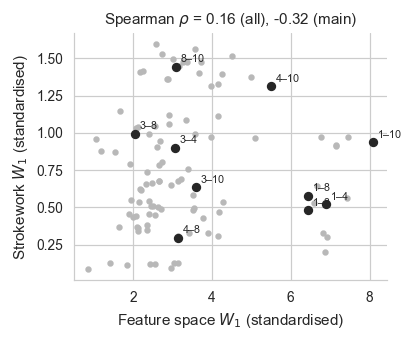

Spearman all pairs:  rho=0.157, p=0.11, n=105
Spearman main pairs: rho=-0.321, p=0.365, n=10 (descriptive only)


In [17]:
# Figure 3 — target distance vs. feature distance (scatter only)
# If only covariate shift were present, the two distances would rank animal pairs similarly.
Wy = y_w_matrix / y_pooled_sd          # target W1 in pooled-SD units
Wx = multi_w_matrix                    # multivariate W1, pooled z-scored features

K = len(all_ids)
iu = np.triu_indices(K, k=1)
wx_all, wy_all = Wx.values[iu], Wy.values[iu]
is_main = np.array([all_ids[i] in main_ids and all_ids[j] in main_ids for i, j in zip(*iu)])

fig, ax = plt.subplots(figsize=(TEXTWIDTH * 0.6, 3.2))
if other_ids:
    ax.scatter(wx_all[~is_main], wy_all[~is_main], s=10, color=OTHER_COLOR, zorder=2)
ax.scatter(wx_all[is_main], wy_all[is_main], s=26, color="0.15", zorder=3)
for (i, j), x, y, im in zip(zip(*iu), wx_all, wy_all, is_main):
    if im:
        ax.annotate(f"{all_ids[i]}–{all_ids[j]}", (x, y), xytext=(3, 3),
                    textcoords="offset points", fontsize=7)

rho_all, p_all = spearmanr(wx_all, wy_all)
rho_main, p_main = spearmanr(wx_all[is_main], wy_all[is_main])
ax.set_xlabel("Feature space $W_1$ (standardised)")
ax.set_ylabel(f"{TARGET_NAME} $W_1$ (standardised)")
ax.set_title(f"Spearman $\\rho$ = {rho_all:.2f} (all), {rho_main:.2f} (main)" if other_ids
             else f"Spearman $\\rho$ = {rho_main:.2f}")
if other_ids:
    ax.legend(frameon=False, fontsize=8, loc="upper left")
sns.despine(ax=ax)
plt.tight_layout()
save(fig, "fig3_target_vs_feature_distance")

print(f"Spearman all pairs:  rho={rho_all:.3f}, p={p_all:.3g}, n={len(wx_all)}")
print(f"Spearman main pairs: rho={rho_main:.3f}, p={p_main:.3g}, n={is_main.sum()} (descriptive only)")

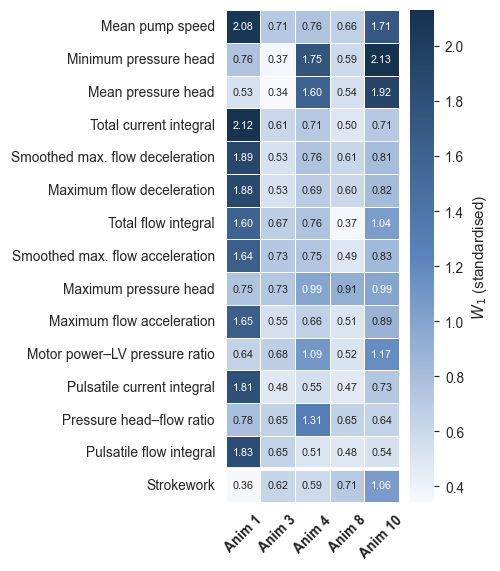

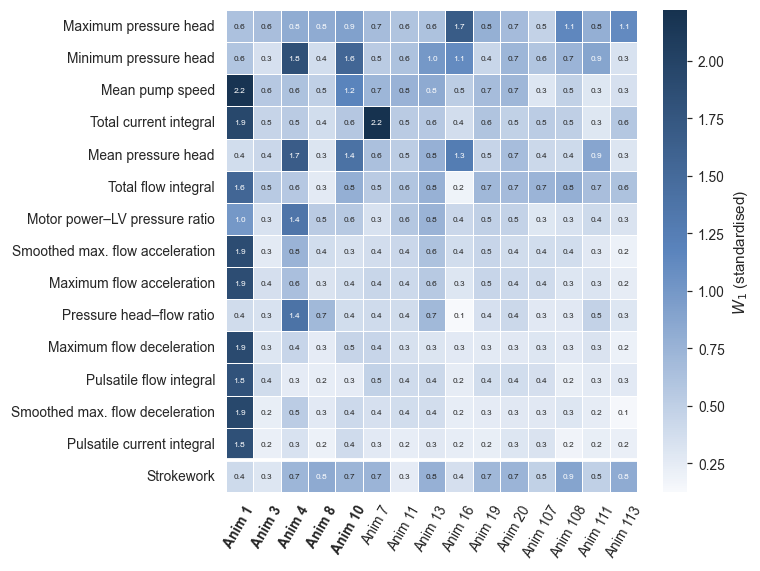

In [18]:
# Figure 4 — covariate shift per feature, LOO view (held-out animal vs. pooled remaining animals)
# Main text: LOO within the main subset. Appendix A1: LOO within all animals.
def loo_shift(ids):
    W = pd.DataFrame(
        {disp(a): [wasserstein_distance(Xz[a][:, f], np.concatenate([Xz[b][:, f] for b in ids if b != a]))
                   for f in range(n_feat)] for a in ids},
        index=feat_names)
    W.loc[TARGET_NAME] = [wasserstein_distance(Y[a], np.concatenate([Y[b] for b in ids if b != a])) / y_pooled_sd
                          for a in ids]
    return W

def plot_loo(W, ids, name, width, fmt, size):
    order = W.drop(TARGET_NAME).mean(axis=1).sort_values(ascending=False).index.tolist() + [TARGET_NAME]
    fig, ax = plt.subplots(figsize=(width, 0.3 * len(order) + 0.8))
    sns.heatmap(W.loc[order], annot=True, fmt=fmt, cmap=HEAT_CMAP, **HEAT_KW, annot_kws={"size": size},
                cbar_kws={"label": "$W_1$ (standardised)"}, ax=ax)
    ax.axhline(len(order) - 1, color="white", lw=2.5)
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=60 if len(ids) > 8 else 45); ax.tick_params(axis="y", rotation=0)
    bold_main(ax.get_xticklabels(), ids)
    plt.tight_layout()
    save(fig, name)
    return order

W_loo_main = loo_shift(main_ids)
order_main = plot_loo(W_loo_main, main_ids, "fig4_feature_shift_loo_main", TEXTWIDTH * 0.7, ".2f", 7)
if other_ids:
    W_loo_all = loo_shift(ids_disp_order)
    plot_loo(W_loo_all, ids_disp_order, "figA1_feature_shift_loo_all", TEXTWIDTH * 1.1, ".1f", 5.5)

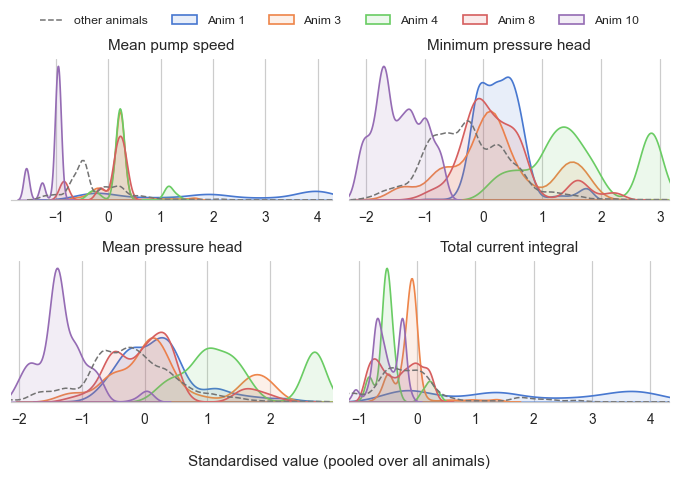

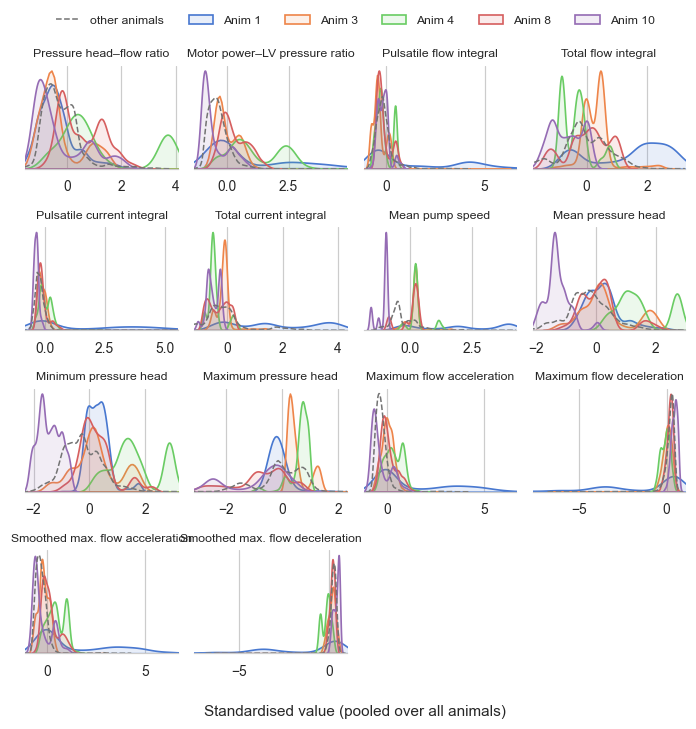

In [19]:
# Figure 5 — marginals of the most-shifted features (main subset; other animals pooled in grey)
# x-axis cropped to the XLIM_PCT percentiles of the main subset. Appendix A2: all features.
def plot_marginals(features, ncols, name, row_h):
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(TEXTWIDTH, row_h * nrows + 0.3), squeeze=False)
    for ax, f in zip(axes.flat, features):
        fi = feat_names.index(f)
        if other_ids:
            sns.kdeplot(np.concatenate([Xz[a][:, fi] for a in other_ids]), ax=ax, color="0.45", lw=1,
                        ls="--", label="other animals", warn_singular=False)
        for a in main_ids:
            sns.kdeplot(Xz[a][:, fi], ax=ax, color=pal_main[a], lw=1.1, fill=True, alpha=0.12,
                        label=disp(a), warn_singular=False)
        lo, hi = np.percentile(np.concatenate([Xz[a][:, fi] for a in main_ids]), XLIM_PCT)
        pad = 0.05 * (hi - lo) if hi > lo else 0.5
        ax.set_xlim(lo - pad, hi + pad)
        ax.set_title(f, fontsize=10 if ncols <= 2 else 8)
        ax.set_ylabel(""); ax.set_yticks([]); ax.set_xlabel("")
        sns.despine(ax=ax, left=True)
    for ax in axes.flat[len(features):]:
        ax.axis("off")
    fig.supxlabel("Standardised value (pooled over all animals)", fontsize=10)
    h, l = axes.flat[0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", ncol=len(l), frameon=False, bbox_to_anchor=(0.5, 1.04), fontsize=8)
    plt.tight_layout()
    save(fig, name)

top_feats = [f for f in order_main if f != TARGET_NAME][:4]
plot_marginals(top_feats, ncols=2, name="fig5_top_feature_marginals", row_h=1.9)
plot_marginals(feat_names, ncols=4, name="figA2_all_feature_marginals", row_h=1.5)

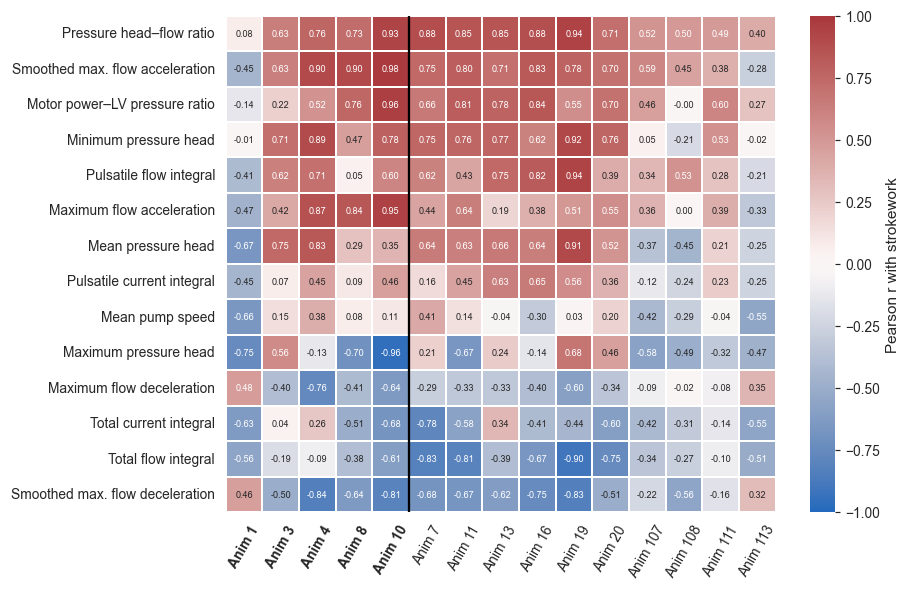

Features where Anim 1 flips sign vs. the median of all other animals: ['dQdtMax_smoothed', 'auc_lvad_flow_only_pulsatile', 'dQdtMax', 'mean_pHead', 'auc_lvad_current_only_pulsatile', 'dQdtMin', 'dQdtMin_smoothed']


In [16]:
# Figure 6 — conditional shift: feature–target correlation per animal (not averaged)
# Main subset first, separated by a line from the other animals.
col_ids = ids_disp_order
corr = pd.DataFrame({disp(a): [np.corrcoef(Xz[a][:, f], Y[a])[0, 1] for f in range(n_feat)] for a in col_ids},
                    index=feat_names)
ref_cols = [disp(a) for a in col_ids if a != TARGET_ID]
corr = corr.loc[corr[ref_cols].mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(max(TEXTWIDTH * 0.6, 0.38 * len(col_ids) + 2.8), 0.32 * n_feat + 1))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, linewidths=0.3,
            annot_kws={"size": 6 if len(col_ids) > 8 else 7},
            cbar_kws={"label": f"Pearson r with {TARGET_NAME.lower()}"}, ax=ax)
if other_ids:
    ax.axvline(len(main_ids), color="black", lw=1.5)
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(axis="x", rotation=60 if len(col_ids) > 8 else 45); ax.tick_params(axis="y", rotation=0)
bold_main(ax.get_xticklabels(), col_ids)
plt.tight_layout()
save(fig, "fig6_feature_target_correlation")

ref_median = corr[ref_cols].median(axis=1)
flips = corr.index[(np.sign(corr[disp(TARGET_ID)]) != np.sign(ref_median))
                   & (corr[disp(TARGET_ID)].abs() > 0.2) & (ref_median.abs() > 0.2)]
print(f"Features where {disp(TARGET_ID)} flips sign vs. the median of all other animals:",
      [raw_feat_names[feat_names.index(f)] for f in flips])

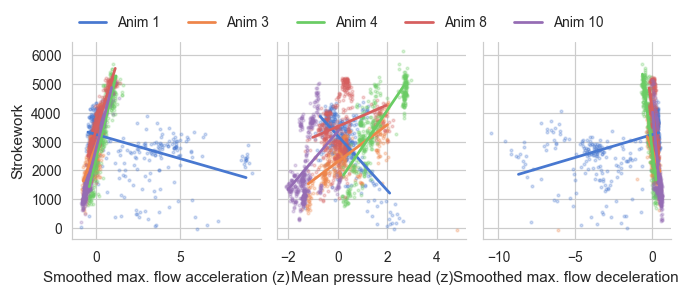

In [17]:
# Figure 7 — conditional shift: target vs. the features that flip most for TARGET_ID (main subset)
# Override COND_FEATURES with your top SHAP features if you prefer (use the column names).
delta = (corr[disp(TARGET_ID)] - corr[ref_cols].mean(axis=1)).abs()
COND_FEATURES = delta.sort_values(ascending=False).index[:3].tolist()
N_SCATTER = 400

fig, axes = plt.subplots(1, len(COND_FEATURES), figsize=(TEXTWIDTH, 2.5), sharey=True)
axes = np.atleast_1d(axes)
for ax, f in zip(axes, COND_FEATURES):
    fi = feat_names.index(f)
    for a in main_ids:
        idx = rng.choice(len(Y[a]), size=min(N_SCATTER, len(Y[a])), replace=False)
        ax.scatter(Xz[a][idx, fi], Y[a][idx], s=3, alpha=0.25, color=pal_main[a], rasterized=True)
        lo, hi = np.percentile(Xz[a][:, fi], [2, 98])
        xs = np.linspace(lo, hi, 50)
        ax.plot(xs, np.polyval(np.polyfit(Xz[a][:, fi], Y[a], 1), xs), color=pal_main[a], lw=1.8, label=disp(a))
    ax.set_xlabel(f"{f} (z)")
    sns.despine(ax=ax)
axes[0].set_ylabel(TARGET_NAME)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=len(l), frameon=False, bbox_to_anchor=(0.5, 1.08))
plt.tight_layout()
save(fig, "fig7_conditional_shift_scatter")

In [18]:
# Check for the text: does the sign flip survive within intervention states? (Simpson's paradox check)
# If r within states has the same sign as overall, the flip is not an artifact of the protocol.
rows = []
for a in main_ids:
    iv = df_selected.loc[df_selected["animal"] == a, "intervention"].reset_index(drop=True)
    for f in COND_FEATURES:
        fi = feat_names.index(f)
        within = []
        for v in iv.dropna().unique():
            m = (iv == v).values
            if m.sum() > 30 and Xz[a][m, fi].std() > 0 and Y[a][m].std() > 0:
                within.append(np.corrcoef(Xz[a][m, fi], Y[a][m])[0, 1])
        rows.append({"Animal": disp(a), "Feature": raw_feat_names[fi],
                     "r overall": np.corrcoef(Xz[a][:, fi], Y[a])[0, 1],
                     "r within (median)": np.median(within) if within else np.nan,
                     "n states": len(within)})
simpson = pd.DataFrame(rows).pivot(index="Feature", columns="Animal")
print(simpson.round(2).to_string())

                 r overall                              r within (median)                              n states                             
Animal              Anim 1 Anim 10 Anim 3 Anim 4 Anim 8            Anim 1 Anim 10 Anim 3 Anim 4 Anim 8   Anim 1 Anim 10 Anim 3 Anim 4 Anim 8
Feature                                                                                                                                     
dQdtMax_smoothed     -0.45    0.98   0.63   0.90   0.90             -0.45    0.75   0.10   0.82   0.85        3       3      4      3      3
dQdtMin_smoothed      0.46   -0.81  -0.50  -0.84  -0.64              0.47   -0.52  -0.31  -0.79  -0.71        3       3      4      3      3
mean_pHead           -0.67    0.35   0.75   0.83   0.29             -0.66    0.49   0.63   0.86   0.71        3       3      4      3      3


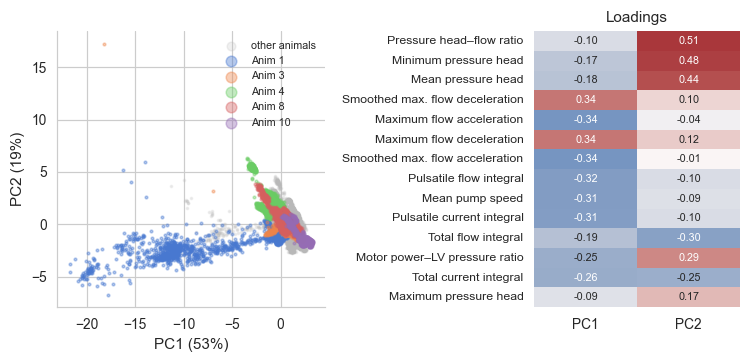

In [19]:
# Figure 8 — PCA embedding (all animals; main subset in colour, others grey) + loadings
X_cat = np.vstack([Xz[a] for a in all_ids])
lab_cat = np.concatenate([[a] * len(Xz[a]) for a in all_ids])
pca = PCA(n_components=2, random_state=SEED).fit(X_cat)
Zp = pca.transform(X_cat)

def scatter_embedding(ax, E):
    m_other = np.isin(lab_cat, other_ids)
    if m_other.any():
        ax.scatter(E[m_other, 0], E[m_other, 1], s=2, alpha=0.2, color=OTHER_COLOR, label="other animals",
                   rasterized=True)
    for a in main_ids:
        m = lab_cat == a
        ax.scatter(E[m, 0], E[m, 1], s=3, alpha=0.4, color=pal_main[a], label=disp(a), rasterized=True)
    ax.legend(markerscale=4, frameon=False, fontsize=7)
    sns.despine(ax=ax)

fig, axes = plt.subplots(1, 2, figsize=(TEXTWIDTH * 1.1, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
scatter_embedding(axes[0], Zp)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
load = pd.DataFrame(pca.components_.T, index=feat_names, columns=["PC1", "PC2"])
load = load.loc[load.abs().max(axis=1).sort_values(ascending=False).index]
sns.heatmap(load, annot=True, fmt=".2f", cmap="vlag", center=0, cbar=False, annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Loadings"); axes[1].tick_params(axis="y", labelsize=8, rotation=0)
plt.tight_layout()
save(fig, "fig8_pca_embedding")

C:\Users\leona\PythonScripts\MasterThesis\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


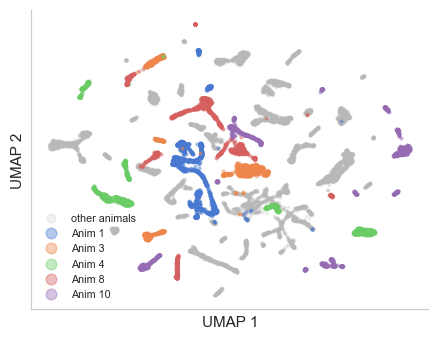

In [20]:
# Figure A3 (appendix) — UMAP embedding, subsampled per animal for speed
N_UMAP = 1500
idx_u = np.concatenate([np.where(lab_cat == a)[0][rng.choice((lab_cat == a).sum(),
                        size=min(N_UMAP, (lab_cat == a).sum()), replace=False)] for a in all_ids])
E = np.full((len(X_cat), 2), np.nan)
E[idx_u] = UMAP(n_neighbors=30, min_dist=0.3, random_state=SEED).fit_transform(X_cat[idx_u])
fig, ax = plt.subplots(figsize=(TEXTWIDTH * 0.65, 3.2))
scatter_embedding(ax, E)
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
plt.tight_layout()
save(fig, "figA3_umap_embedding")

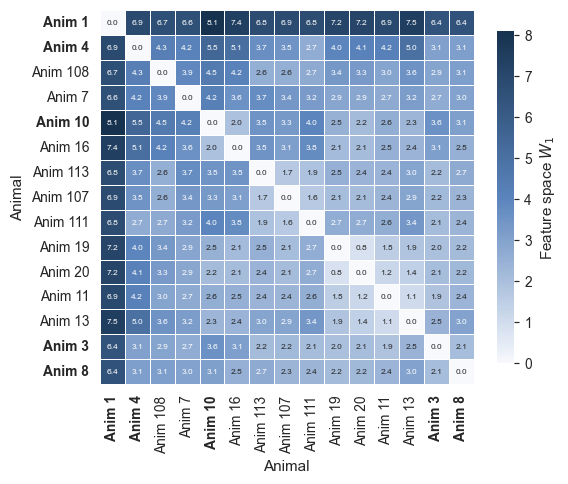

In [21]:
# Figure 9 — cohort overview: feature-space W1 between all animals, ordered by hierarchical clustering
# Shows where the main subset sits within the full cohort (main animals in bold).
if other_ids:
    D = multi_w_matrix.values
    o = leaves_list(linkage(squareform(D, checks=False), method="average"))
    ids_o = [all_ids[i] for i in o]
    fig, ax = plt.subplots(figsize=(TEXTWIDTH * 0.85, TEXTWIDTH * 0.75))
    sns.heatmap(multi_w_matrix.iloc[o, o].values, annot=len(all_ids) <= 18, fmt=".1f", annot_kws={"size": 5.5},
                cmap=HEAT_CMAP, **HEAT_KW, square=True,
                xticklabels=[disp(a) for a in ids_o], yticklabels=[disp(a) for a in ids_o],
                cbar_kws={"label": "Feature space $W_1$", "shrink": 0.8}, ax=ax)
    ax.tick_params(axis="y", rotation=0); ax.tick_params(axis="x", rotation=90)
    bold_main(ax.get_xticklabels(), ids_o); bold_main(ax.get_yticklabels(), ids_o)
    ax.set_xlabel("Animal"); ax.set_ylabel("Animal")
    plt.tight_layout()
    save(fig, "fig9_cohort_feature_distance")

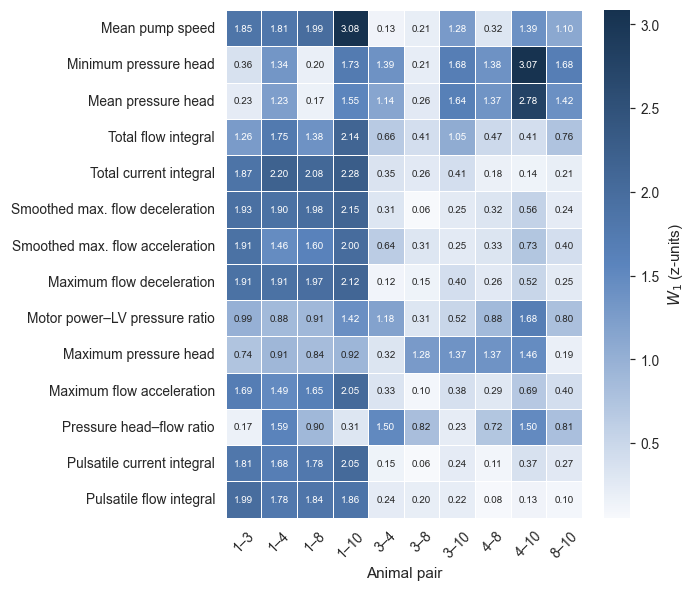

In [22]:
# Figure A4 (appendix) — per-feature W1 for every pair within the main subset (from feature_w_matrix above)
def pair_col(a, b):
    for c in (f"Anim {a} vs {b}", f"Anim {b} vs {a}"):
        if c in feature_w_matrix.columns:
            return c
main_pairs = list(itertools.combinations(main_ids, 2))
W_pairs = feature_w_matrix[[pair_col(a, b) for a, b in main_pairs]].copy()
W_pairs.columns = [f"{a}–{b}" for a, b in main_pairs]
W_pairs.index = [FEATURE_LABELS.get(str(c), str(c).replace("_", " ")) for c in W_pairs.index]
W_pairs = W_pairs.loc[W_pairs.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(TEXTWIDTH, 0.32 * n_feat + 1))
sns.heatmap(W_pairs, annot=True, fmt=".2f", cmap=HEAT_CMAP, **HEAT_KW, annot_kws={"size": 6.5},
            cbar_kws={"label": "$W_1$ (z-units)"}, ax=ax)
ax.set_xlabel("Animal pair"); ax.set_ylabel("")
ax.tick_params(axis="x", rotation=45); ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
save(fig, "figA4_feature_shift_pairwise_main")

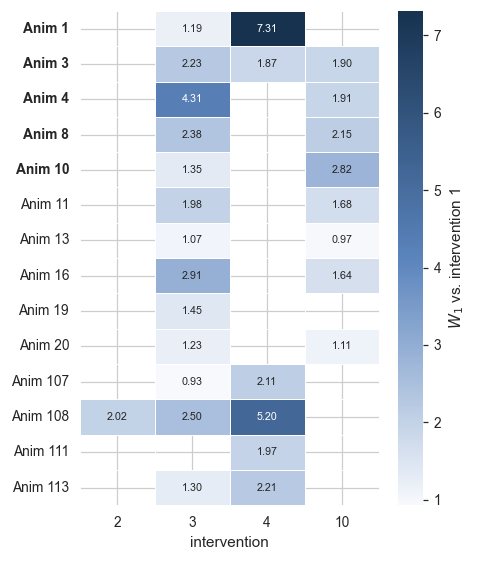

Within-animal W1: median 1.94, max 7.31
Between-animal W1: median 2.95, range 0.85–8.09


In [23]:
# Figure A5 (appendix) — within-animal shift: W1 of each intervention vs. the baseline state
# Same scaler and metric as the between-animal W1, so the numbers are directly comparable with Fig. 3 / 9.
BASELINE = phases[0]              # set explicitly if the pre-intervention state is not the smallest value
N_MAX = 2000                      # cap per state to keep exact OT tractable

def cap(A):
    return A[rng.choice(len(A), size=N_MAX, replace=False)] if len(A) > N_MAX else A

def w1_exact(A, B):
    return ot.emd2(ot.unif(len(A)), ot.unif(len(B)), ot.dist(A, B, metric="euclidean"), numItermax=1_000_000)

rows = []
for a in ids_disp_order:
    iv = df_selected.loc[df_selected["animal"] == a, "intervention"].reset_index(drop=True)
    base_mask = (iv == BASELINE).values
    if base_mask.sum() < 20:
        continue
    B = cap(Xz[a][base_mask])
    for v in phases:
        m = (iv == v).values
        if v == BASELINE or m.sum() < 20:
            continue
        rows.append({"Animal": a, "intervention": v, "W1": w1_exact(cap(Xz[a][m]), B)})

if rows:
    W_int = pd.DataFrame(rows).pivot(index="Animal", columns="intervention", values="W1")
    W_int = W_int.loc[[a for a in ids_disp_order if a in W_int.index], sorted(W_int.columns, key=num_key)]
    fig, ax = plt.subplots(figsize=(TEXTWIDTH * 0.7, 0.3 * len(W_int) + 1))
    sns.heatmap(W_int, annot=True, fmt=".2f", cmap=HEAT_CMAP, **HEAT_KW, annot_kws={"size": 7},
                cbar_kws={"label": f"$W_1$ vs. intervention {BASELINE}"}, ax=ax)
    ax.set_yticklabels([disp(a) for a in W_int.index], rotation=0)
    bold_main(ax.get_yticklabels(), list(W_int.index))
    ax.set_xlabel("intervention"); ax.set_ylabel("")
    plt.tight_layout()
    save(fig, "figA5_within_animal_shift")
    between = multi_w_matrix.values[np.triu_indices(len(all_ids), 1)]
    print(f"Within-animal W1: median {np.nanmedian(W_int.values):.2f}, max {np.nanmax(W_int.values):.2f}")
    print(f"Between-animal W1: median {np.median(between):.2f}, range {between.min():.2f}–{between.max():.2f}")
else:
    print("No animal has enough samples in the baseline state -> set BASELINE explicitly")